# Scoring de résiliation client (*churn*) dans une banque

**Auteure :** Rhina Monika LACMOU DZUFO · [LinkedIn](https://www.linkedin.com/in/rhina-lacmou-dzufo) · [GitHub](https://github.com/iammonika10)

## Objectif

Dans une banque, garder un client coûte beaucoup moins cher que d'en conquérir un nouveau. L'objectif de ce projet est
de construire un **score de résiliation** : pour chaque client, la probabilité qu'il quitte la banque. La banque peut
ensuite classer ses clients du moins risqué au plus risqué et concentrer ses actions de fidélisation là où elles comptent.

## Données

Jeu de données public *Churn Modelling* (Kaggle) : **10 000 clients** d'une banque présente en France, en Allemagne et en
Espagne, décrits par 10 variables (âge, ancienneté, solde, nombre de produits, pays…). La cible `Exited` vaut 1 si le
client est parti (20,4 % des clients).

## Résultats clés

- Meilleur modèle : **HistGradientBoosting**, avec une **AUC de 0,874** sur le jeu de test.
- En contactant les **20 %** de clients les plus à risque, la banque repère **64 %** des départs, soit plus de 3 fois mieux qu'un ciblage au hasard.
- Les probabilités prédites sont **bien calibrées** : elles correspondent aux taux de départ réellement observés.
- Facteurs principaux : l'**âge**, le **nombre de produits** (effet en U), le **pays** (Allemagne), le **solde** et l'**activité** du client.

## Plan

1. Exploration et préparation des données
2. Régression logistique pénalisée (Ridge et Lasso)
3. Méthodes locales (K plus proches voisins, arbre de décision)
4. Méthodes d'ensemble (forêt aléatoire, HistGradientBoosting)
5. Courbes d'apprentissage et compromis biais-variance
6. Interprétation et recommandations métier

Outils : `pandas`, `numpy`, `matplotlib`, `seaborn` et `scikit-learn` uniquement (versions dans `requirements.txt`).

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn 1.8 annonce un changement futur du paramètre `penalty` de LogisticRegression :
# le code reste valable, je masque seulement ces avertissements pour garder le notebook lisible.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Inconsistent values: penalty")
warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")

sns.set_theme(style="whitegrid")

In [2]:
chemin = Path("data") / "Churn_Modelling.csv"
if not chemin.exists():
    raise FileNotFoundError("Fichier introuvable : télécharge Churn_Modelling.csv (voir le README) "
                            "et place-le dans le dossier data/.")

df = pd.read_csv(chemin)
# RowNumber, CustomerId et Surname sont des identifiants : ils n'aident pas à prédire un départ
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

print("Dimensions :", df.shape)
print(f"Taux de résiliation : {df['Exited'].mean():.1%}")
print("Valeurs manquantes :", df.isna().sum().sum())
df.head()

Dimensions : (10000, 11)
Taux de résiliation : 20.4%
Valeurs manquantes : 0


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Partie 1 — Exploration et préparation des données

### 1.1 Distributions des variables numériques

Je compare la distribution de chaque variable numérique entre les clients qui partent (`Exited = 1`) et ceux qui
restent (`Exited = 0`). Plus les deux courbes sont décalées, plus la variable est *discriminante*.

,Age,Balance,CreditScore,EstimatedSalary
Exited,,,,
0,37.4,72745.3,651.9,99738.4
1,44.8,91108.5,645.4,101465.7


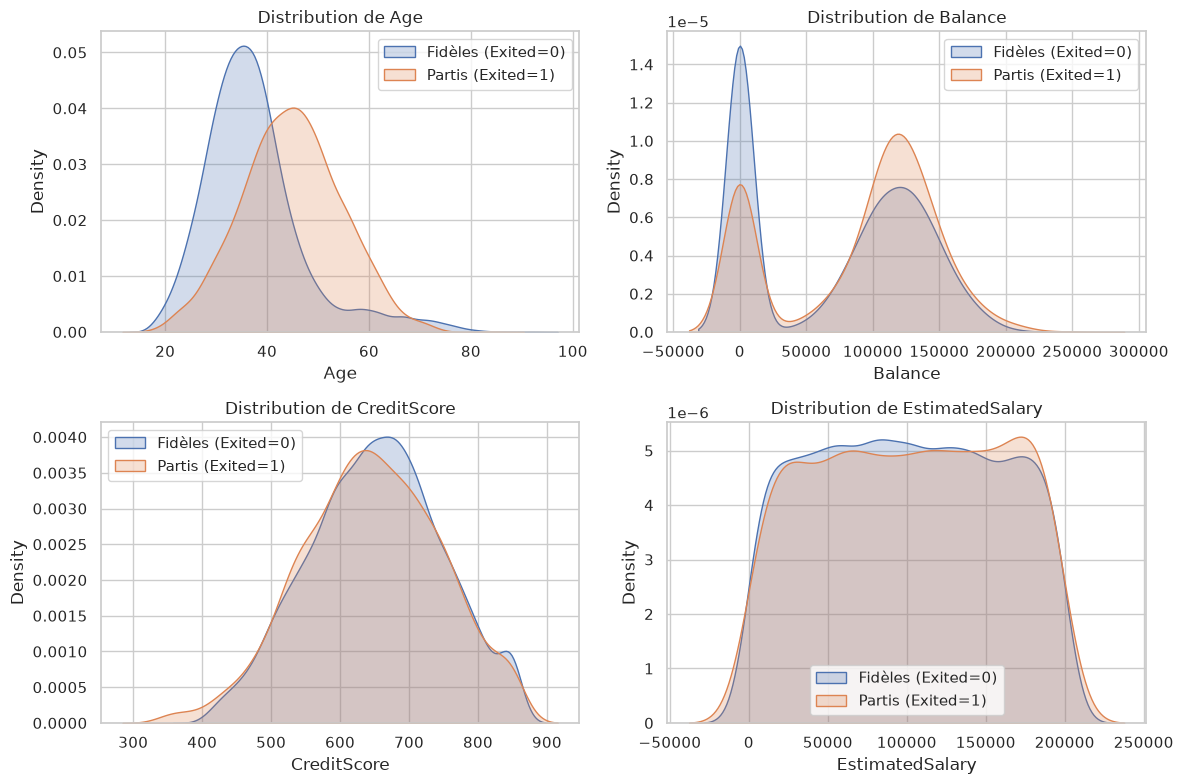

In [3]:
variables_num = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary']

# Moyennes selon que le client reste (0) ou part (1)
display(df.groupby('Exited')[variables_num].mean().round(1))

clients_fideles = df[df['Exited'] == 0]
clients_partis = df[df['Exited'] == 1]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), variables_num):
    sns.kdeplot(clients_fideles[col], label='Fidèles (Exited=0)', fill=True, ax=ax)
    sns.kdeplot(clients_partis[col], label='Partis (Exited=1)', fill=True, ax=ax)
    ax.set_title(f"Distribution de {col}")
    ax.legend()
plt.tight_layout()
plt.show()

**Ce que je retiens :** l'**âge** est la variable la plus discriminante : les courbes sont nettement décalées
(44,8 ans en moyenne chez les clients partis contre 37,4 ans chez les fidèles). Le **solde** (`Balance`) sépare un peu
les deux groupes (91 109 contre 72 745 en moyenne). En revanche, les courbes du `CreditScore` et de
l'`EstimatedSalary` se superposent presque : seules, ces variables distinguent mal les clients qui partent.

### 1.2 Taux de résiliation par variable catégorielle

La ligne pointillée représente le taux moyen (20,4 %) : une barre au-dessus signale un groupe plus à risque que la moyenne.

Taux de résiliation par Geography : {'France': 0.162, 'Germany': 0.324, 'Spain': 0.167}
Taux de résiliation par Gender : {'Female': 0.251, 'Male': 0.165}
Taux de résiliation par NumOfProducts : {1: 0.277, 2: 0.076, 3: 0.827, 4: 1.0}
Taux de résiliation par HasCrCard : {0: 0.208, 1: 0.202}
Taux de résiliation par IsActiveMember : {0: 0.269, 1: 0.143}


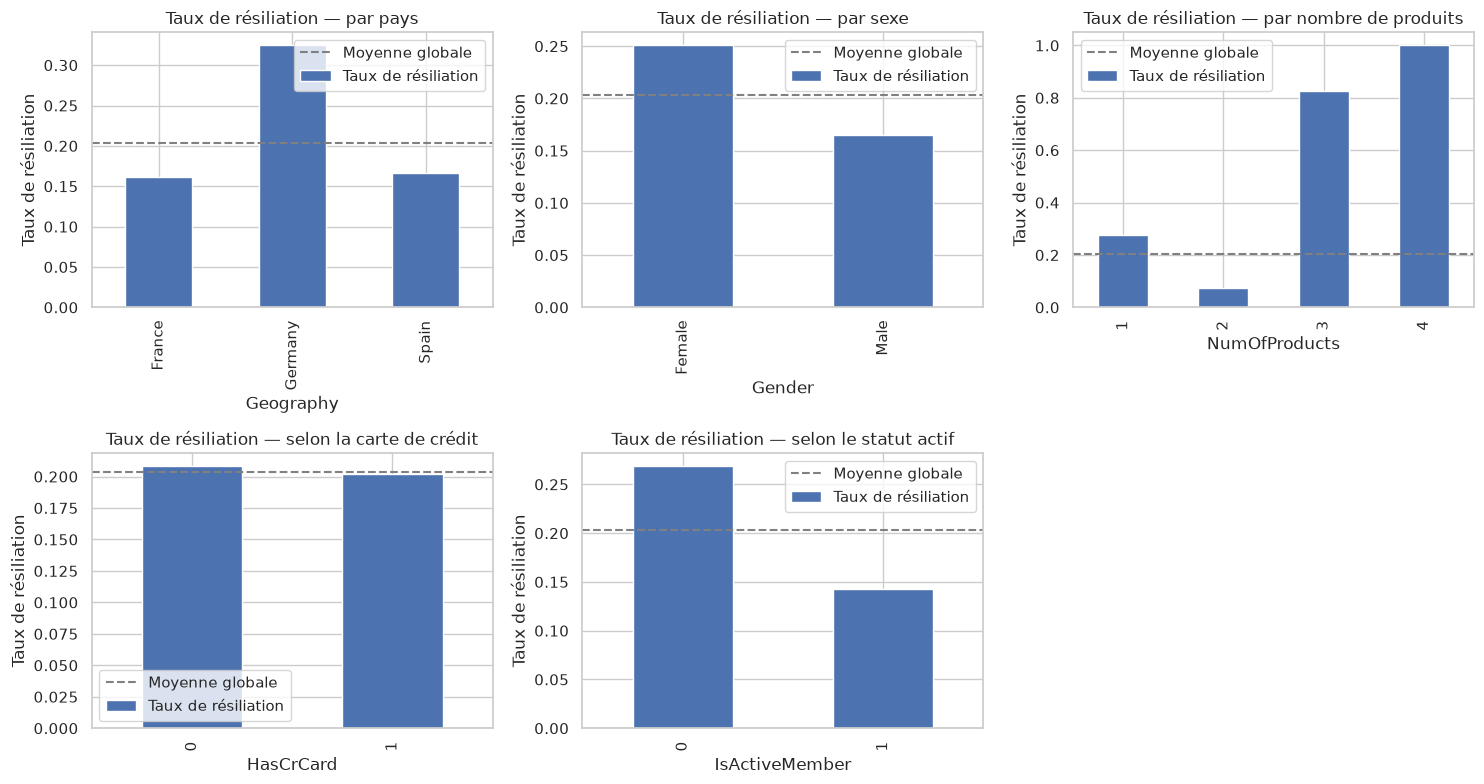

Nombre de clients par nombre de produits : {1: 5084, 2: 4590, 3: 266, 4: 60}


In [4]:
variables_cat = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember']
titres = ["Par pays", "Par sexe", "Par nombre de produits", "Selon la carte de crédit", "Selon le statut actif"]
taux_global = df['Exited'].mean()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col, titre in zip(axes.flatten(), variables_cat, titres):
    taux = df.groupby(col)['Exited'].mean()
    print(f"Taux de résiliation par {col} :", taux.round(3).to_dict())
    taux.rename('Taux de résiliation').plot(kind='bar', ax=ax)
    ax.axhline(taux_global, color='gray', linestyle='--', label='Moyenne globale')
    ax.set_title(f"Taux de résiliation — {titre.lower()}")
    ax.set_ylabel("Taux de résiliation")
    ax.legend()
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

print("Nombre de clients par nombre de produits :", df['NumOfProducts'].value_counts().sort_index().to_dict())

**Ce que je retiens :**

- **Pays :** l'Allemagne compte 32,4 % de départs, près du double de la France (16,2 %) et de l'Espagne (16,7 %).
- **Sexe :** les femmes partent davantage que les hommes (25,1 % contre 16,5 %).
- **Nombre de produits :** l'effet est en « U ». 27,7 % de départs avec 1 produit, seulement 7,6 % avec 2, mais 82,7 %
  avec 3 et 100 % avec 4 (ces deux derniers groupes ne comptent que 326 clients). Un modèle linéaire aura du mal à
  capter cette forme.
- **Activité :** les clients inactifs partent presque deux fois plus (26,9 % contre 14,3 %).
- **Carte de crédit :** elle ne change rien (20,8 % contre 20,2 %).

### 1.3 Ancienneté (*Tenure*) et fidélité

{0: 0.23, 1: 0.224, 2: 0.192, 3: 0.211, 4: 0.205, 5: 0.207, 6: 0.203, 7: 0.172, 8: 0.192, 9: 0.216, 10: 0.206}


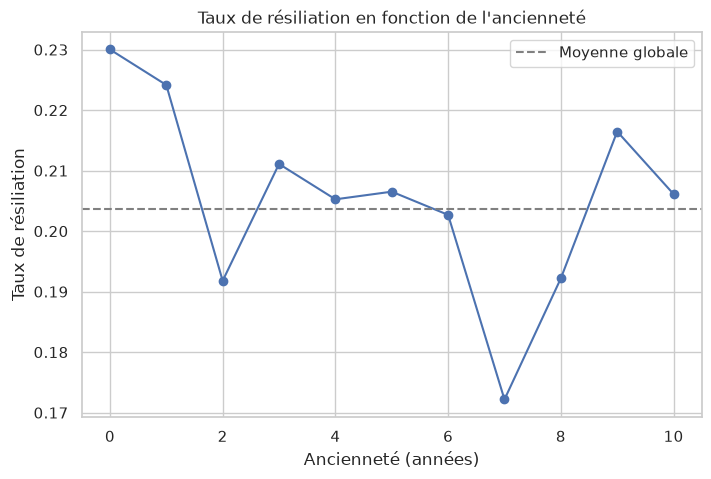

In [5]:
taux_tenure = df.groupby('Tenure')['Exited'].mean()
print(taux_tenure.round(3).to_dict())

plt.figure(figsize=(8, 5))
plt.plot(taux_tenure.index, taux_tenure.values, marker='o')
plt.axhline(taux_global, color='gray', linestyle='--', label='Moyenne globale')
plt.title("Taux de résiliation en fonction de l'ancienneté")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Taux de résiliation")
plt.legend()
plt.show()

**Ce que je retiens :** le taux de départ est un peu plus élevé les deux premières années (23,0 % puis 22,4 %), puis il
oscille autour de 20 % sans tendance nette. La fidélité n'augmente donc pas avec l'ancienneté. On ne retrouve pas le
schéma actuariel classique, où les mauvais risques partent tôt puis les clients restants se fidélisent : il s'agit ici
de comptes bancaires, sans échéance annuelle comme en assurance.

### 1.4 Création de trois nouvelles variables (*feature engineering*)

- **`Balance_zero`** : 1 si le solde est nul. Mon hypothèse : un compte vide peut annoncer un client qui se désengage.
- **`Products_ratio`** : nombre de produits divisé par (ancienneté + 1), c'est-à-dire la vitesse à laquelle le client
  s'équipe (le +1 évite de diviser par zéro).
- **`Engagement_score`** : un score de 0 à 3 qui additionne trois signaux de bonne relation : client actif, détenteur
  d'une carte, et au moins 2 produits.

In [6]:
df_nouvel = df.copy()

df_nouvel['Balance_zero'] = (df_nouvel['Balance'] == 0).astype(int)
df_nouvel['Products_ratio'] = df_nouvel['NumOfProducts'] / (df_nouvel['Tenure'] + 1)
df_nouvel['Engagement_score'] = (df_nouvel['IsActiveMember'] + df_nouvel['HasCrCard']
                                 + (df_nouvel['NumOfProducts'] >= 2).astype(int))

print("Taux de résiliation selon Balance_zero :", df_nouvel.groupby('Balance_zero')['Exited'].mean().round(3).to_dict())
print("Products_ratio moyen (0 = reste, 1 = part) :", df_nouvel.groupby('Exited')['Products_ratio'].mean().round(3).to_dict())
print("Taux de résiliation selon Engagement_score :", df_nouvel.groupby('Engagement_score')['Exited'].mean().round(3).to_dict())

Taux de résiliation selon Balance_zero : {0: 0.241, 1: 0.138}
Products_ratio moyen (0 = reste, 1 = part) : {0: 0.368, 1: 0.363}
Taux de résiliation selon Engagement_score : {0: 0.345, 1: 0.293, 2: 0.159, 3: 0.091}


**Ce que je retiens :**

- **`Balance_zero`** : les données contredisent mon hypothèse. Les clients au solde nul partent **moins** (13,8 %) que
  les autres (24,1 %) : un compte vide n'est pas un signal de départ.
- **`Products_ratio`** : sa moyenne est presque identique chez les clients qui partent et ceux qui restent (0,363 contre
  0,368). Seule, cette variable apporte peu.
- **`Engagement_score`** : plus le client coche de cases, moins il part, de 34,5 % de départs à 0 point à 9,1 % à 3 points.

### 1.5 Préparation de la matrice finale $X$

1. **Encodage one-hot** de `Geography` et `Gender` : un modèle ne sait pas travailler directement avec du texte.
2. **Découpage stratifié** : 75 % des clients pour l'entraînement, 25 % pour le test, avec le même taux de départs.
3. **Standardisation** des variables continues (moyenne 0, écart-type 1), indispensable pour la régression pénalisée
   et le K-NN. Le `StandardScaler` est ajusté sur le train seulement, pour éviter toute fuite d'information vers le test.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

X = df_nouvel.drop(columns=['Exited'])
y = df_nouvel['Exited']

X = pd.get_dummies(X, columns=['Geography', 'Gender'], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

variables_numeriques = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Products_ratio']
mon_pipeline = Pipeline([('scaler', StandardScaler())])

X_train = X_train.copy()
X_test = X_test.copy()
X_train[variables_numeriques] = mon_pipeline.fit_transform(X_train[variables_numeriques])
X_test[variables_numeriques] = mon_pipeline.transform(X_test[variables_numeriques])

print("Train :", X_train.shape, "| Test :", X_test.shape)
print(f"Taux de résiliation — train : {y_train.mean():.1%} | test : {y_test.mean():.1%}")

Train : (7500, 14) | Test : (2500, 14)
Taux de résiliation — train : 20.4% | test : 20.4%


## Partie 2 — Régression logistique pénalisée

C'est le modèle de référence : linéaire, rapide et interprétable. La pénalisation limite la taille des coefficients :
**Ridge** (L2) les réduit, **Lasso** (L1) peut les annuler et sélectionne donc les variables. Le paramètre `C` (l'inverse
de la force de pénalisation) est choisi par **validation croisée à 5 plis**, en maximisant l'AUC.

### 2.1 Régression Ridge

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, roc_curve, f1_score

valeurs_C = {'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

modele_ridge = LogisticRegression(penalty='l2', solver='lbfgs', max_iter=1000)
recherche_ridge = GridSearchCV(modele_ridge, valeurs_C, cv=5, scoring='roc_auc')
recherche_ridge.fit(X_train, y_train)

meilleur_ridge = recherche_ridge.best_estimator_
print("Meilleur paramètre C :", recherche_ridge.best_params_['C'])

coeffs_ridge = pd.DataFrame({'Variable': X_train.columns, 'Coefficient': meilleur_ridge.coef_[0]})
coeffs_ridge['Valeur_Absolue'] = coeffs_ridge['Coefficient'].abs()
coeffs_ridge = coeffs_ridge.sort_values(by='Valeur_Absolue', ascending=False)
display(coeffs_ridge.head(10).round(3))

Meilleur paramètre C : 10


,Variable,Coefficient,Valeur_Absolue
10,Engagement_score,-5.542,5.542
5,HasCrCard,5.447,5.447
6,IsActiveMember,4.493,4.493
4,NumOfProducts,2.287,2.287
11,Geography_Germany,1.024,1.024
1,Age,0.705,0.705
13,Gender_Male,-0.487,0.487
8,Balance_zero,0.390,0.390
3,Balance,0.111,0.111
9,Products_ratio,0.098,0.098


La validation croisée retient `C = 10`. Les plus gros coefficients sont ceux d'`Engagement_score` (−5,5), `HasCrCard`
(+5,4) et `IsActiveMember` (+4,5). **Attention à ne pas les lire trop vite :** `Engagement_score` est construit à partir
de `HasCrCard` et `IsActiveMember`. Ces variables sont donc fortement liées (colinéarité) et leurs coefficients se
compensent. L'effet réel de la carte de crédit est d'environ +5,4 − 5,5 ≈ −0,1 (quasi nul, comme en 1.2), et celui du
statut actif d'environ +4,5 − 5,5 ≈ −1,0 (les clients actifs partent moins).

Pour le vérifier, je remplace `Engagement_score` par sa seule composante nouvelle : « au moins 2 produits ».

In [9]:
deux_produits_train = (df_nouvel.loc[X_train.index, 'NumOfProducts'] >= 2).astype(int)
deux_produits_test = (df_nouvel.loc[X_test.index, 'NumOfProducts'] >= 2).astype(int)
X_train_verif = X_train.drop(columns=['Engagement_score']).assign(Deux_produits_ou_plus=deux_produits_train)
X_test_verif = X_test.drop(columns=['Engagement_score']).assign(Deux_produits_ou_plus=deux_produits_test)

ridge_verif = LogisticRegression(penalty='l2', C=recherche_ridge.best_params_['C'], max_iter=1000)
ridge_verif.fit(X_train_verif, y_train)

print("AUC test :", round(roc_auc_score(y_test, ridge_verif.predict_proba(X_test_verif)[:, 1]), 3))
print(pd.Series(ridge_verif.coef_[0], index=X_train_verif.columns).sort_values(key=abs, ascending=False).round(2))

AUC test : 0.847
Deux_produits_ou_plus   -5.57
NumOfProducts            2.30
IsActiveMember          -1.05
Geography_Germany        1.03
Age                      0.70
Gender_Male             -0.49
Balance_zero             0.38
Balance                  0.11
Products_ratio           0.10
HasCrCard               -0.09
CreditScore             -0.08
Geography_Spain          0.07
Tenure                   0.06
EstimatedSalary          0.06
dtype: float64


Même AUC (0,847), mais des coefficients enfin lisibles : « au moins 2 produits » (−5,6) et le nombre de produits (+2,3)
traduisent ensemble l'effet en U vu en 1.2, le statut actif vaut −1,0 et la carte de crédit −0,1. Le pouvoir prédictif
d'`Engagement_score` vient donc surtout de son indicateur « au moins 2 produits ».

### 2.2 Chemin de régularisation du Lasso

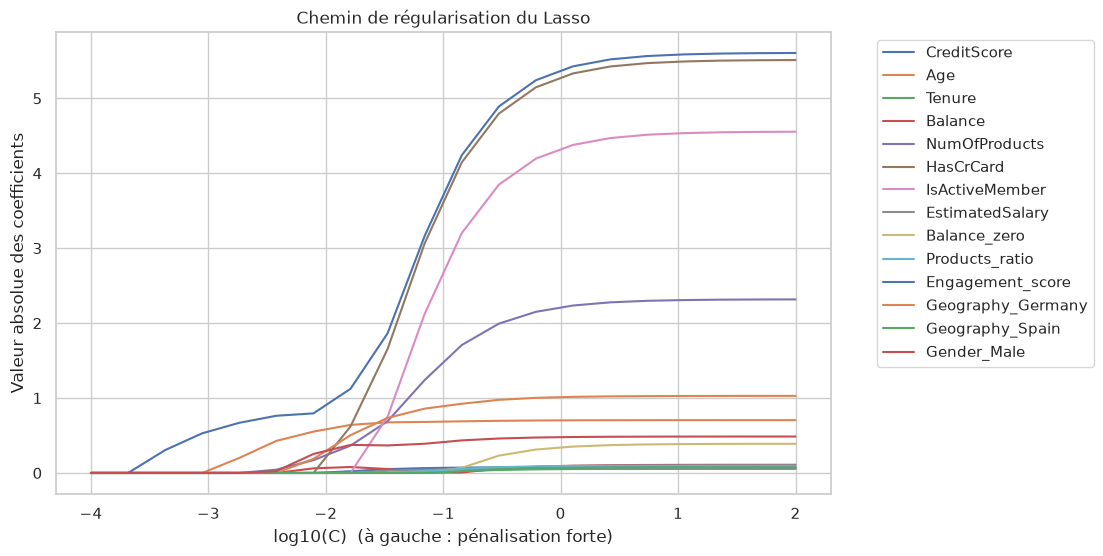

log10(C) à partir duquel chaque variable est conservée (les premières listées sont éliminées en premier) :
Geography_Spain     -0.84
Balance_zero        -0.84
Tenure              -0.84
IsActiveMember      -1.47
Products_ratio      -1.47
EstimatedSalary     -1.79
CreditScore         -1.79
HasCrCard           -1.79
Geography_Germany   -2.11
Balance             -2.11
NumOfProducts       -2.42
Gender_Male         -2.42
Age                 -2.74
Engagement_score    -3.37
dtype: float64


In [10]:
valeurs_C_lasso = np.logspace(-4, 2, 20)
coeffs_lasso_chemin = []

for c in valeurs_C_lasso:
    lasso = LogisticRegression(penalty='l1', solver='liblinear', random_state=42, C=c, max_iter=1000)
    lasso.fit(X_train, y_train)
    coeffs_lasso_chemin.append(lasso.coef_[0])

coeffs_lasso_chemin = np.array(coeffs_lasso_chemin)

plt.figure(figsize=(10, 6))
for i in range(coeffs_lasso_chemin.shape[1]):
    plt.plot(np.log10(valeurs_C_lasso), abs(coeffs_lasso_chemin[:, i]), label=X_train.columns[i])
plt.xlabel("log10(C)  (à gauche : pénalisation forte)")
plt.ylabel("Valeur absolue des coefficients")
plt.title("Chemin de régularisation du Lasso")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# Ordre d'élimination : pour chaque variable, le plus petit C à partir duquel son coefficient n'est plus nul
entree = {}
for c, coefs in zip(valeurs_C_lasso, coeffs_lasso_chemin):
    for variable, coef in zip(X_train.columns, coefs):
        if abs(coef) > 1e-8 and variable not in entree:
            entree[variable] = round(np.log10(c), 2)
print("log10(C) à partir duquel chaque variable est conservée (les premières listées sont éliminées en premier) :")
print(pd.Series(entree).sort_values(ascending=False))

Quand la pénalisation augmente (vers la gauche du graphique), les premières variables à tomber à zéro sont `Tenure`,
`Geography_Spain` et `Balance_zero`, puis `IsActiveMember` et `Products_ratio`, puis `CreditScore`, `HasCrCard` et
`EstimatedSalary`. Les plus résistantes sont `Engagement_score`, `Age` et `NumOfProducts`.

C'est cohérent avec l'exploration : l'ancienneté n'a pas d'effet (1.3), le score de crédit et le salaire distinguent mal
les clients (1.1), et l'Espagne ne se différencie pas de la France (1.2). `IsActiveMember` tombe tôt parce
qu'`Engagement_score` porte déjà une partie de son information.

### 2.3 Évaluation sur le jeu de test

Ridge -> AUC : 0.847 | F1-score : 0.492
Lasso -> AUC : 0.847 | F1-score : 0.495


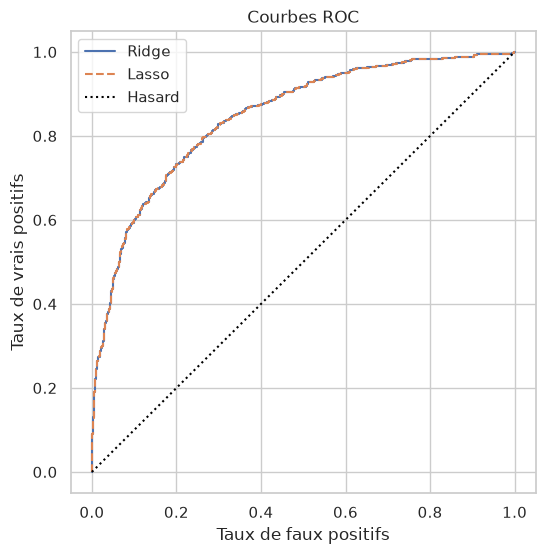

In [11]:
recherche_lasso = GridSearchCV(LogisticRegression(penalty='l1', solver='liblinear', random_state=42, max_iter=1000),
                               valeurs_C, cv=5, scoring='roc_auc')
recherche_lasso.fit(X_train, y_train)
meilleur_lasso = recherche_lasso.best_estimator_

prob_ridge = meilleur_ridge.predict_proba(X_test)[:, 1]
prob_lasso = meilleur_lasso.predict_proba(X_test)[:, 1]

print(f"Ridge -> AUC : {roc_auc_score(y_test, prob_ridge):.3f} | F1-score : {f1_score(y_test, meilleur_ridge.predict(X_test)):.3f}")
print(f"Lasso -> AUC : {roc_auc_score(y_test, prob_lasso):.3f} | F1-score : {f1_score(y_test, meilleur_lasso.predict(X_test)):.3f}")

fpr_r, tpr_r, _ = roc_curve(y_test, prob_ridge)
fpr_l, tpr_l, _ = roc_curve(y_test, prob_lasso)

plt.figure(figsize=(6, 6))
plt.plot(fpr_r, tpr_r, label="Ridge")
plt.plot(fpr_l, tpr_l, label="Lasso", linestyle="--")
plt.plot([0, 1], [0, 1], color="black", linestyle=":", label="Hasard")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.title("Courbes ROC")
plt.legend()
plt.show()

Ridge et Lasso font jeu égal, avec une AUC de 0,847 sur le test. Le F1-score reste modeste (environ 0,49) : avec le
seuil par défaut de 0,5, le modèle repère peu de clients partants, car les départs ne représentent que 20 % des données.
L'AUC, qui ne dépend pas du seuil, est plus adaptée pour comparer les modèles.

### 2.4 Apport des variables construites

In [12]:
colonnes_en_moins = ['Balance_zero', 'Products_ratio', 'Engagement_score']
X_train_sans = X_train.drop(columns=colonnes_en_moins)
X_test_sans = X_test.drop(columns=colonnes_en_moins)

lasso_sans = LogisticRegression(penalty='l1', solver='liblinear', random_state=42, C=recherche_lasso.best_params_['C'], max_iter=1000)
lasso_sans.fit(X_train_sans, y_train)
prob_sans = lasso_sans.predict_proba(X_test_sans)[:, 1]

print("AUC avec mes 3 variables :", round(roc_auc_score(y_test, prob_lasso), 4))
print("AUC sans mes 3 variables :", round(roc_auc_score(y_test, prob_sans), 4))

# Coefficients retenus par le Lasso pour mes variables
coeffs_lasso_final = pd.Series(meilleur_lasso.coef_[0], index=X_train.columns)
print(coeffs_lasso_final[colonnes_en_moins].round(3))

# D'où vient le gain ? Test avec le seul indicateur « au moins 2 produits »
lasso_2p = LogisticRegression(penalty='l1', solver='liblinear', random_state=42, C=recherche_lasso.best_params_['C'], max_iter=1000)
lasso_2p.fit(X_train_sans.assign(Deux_produits_ou_plus=deux_produits_train), y_train)
prob_2p = lasso_2p.predict_proba(X_test_sans.assign(Deux_produits_ou_plus=deux_produits_test))[:, 1]
print("AUC sans mes 3 variables, mais avec « au moins 2 produits » :", round(roc_auc_score(y_test, prob_2p), 4))

AUC avec mes 3 variables : 0.8471
AUC sans mes 3 variables : 0.7836
Balance_zero        0.390
Products_ratio      0.099
Engagement_score   -5.608
dtype: float64
AUC sans mes 3 variables, mais avec « au moins 2 produits » : 0.8468


Mes trois variables font passer l'AUC de 0,784 à 0,847, et le Lasso les conserve toutes. Le dernier test montre d'où
vient ce gain : l'indicateur « au moins 2 produits » suffit à lui seul à retrouver 0,847. Il permet au modèle linéaire
de capter l'**effet en U du nombre de produits**, impossible à représenter avec la seule variable `NumOfProducts`.

## Partie 3 — Méthodes locales

### 3.1 K plus proches voisins (K-NN)

k =   5 -> AUC validation croisée : 0.785


k =  10 -> AUC validation croisée : 0.809


k =  20 -> AUC validation croisée : 0.829


k =  50 -> AUC validation croisée : 0.837


k = 100 -> AUC validation croisée : 0.833


k = 200 -> AUC validation croisée : 0.825


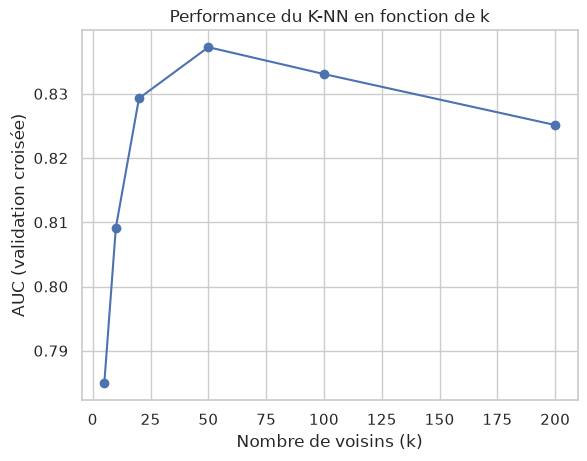

k optimal : 50


In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

valeurs_k = [5, 10, 20, 50, 100, 200]
scores_auc_knn = []

for k in valeurs_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X_train, y_train, cv=5, scoring='roc_auc').mean()
    scores_auc_knn.append(score)
    print(f"k = {k:>3} -> AUC validation croisée : {score:.3f}")

plt.figure()
plt.plot(valeurs_k, scores_auc_knn, marker='o')
plt.xlabel("Nombre de voisins (k)")
plt.ylabel("AUC (validation croisée)")
plt.title("Performance du K-NN en fonction de k")
plt.show()

meilleur_k = valeurs_k[int(np.argmax(scores_auc_knn))]
print("k optimal :", meilleur_k)

L'AUC progresse jusqu'à **k = 50** (0,837), puis redescend (0,825 à k = 200). Avec trop peu de voisins (k = 5 : 0,785),
le modèle colle au bruit ; avec trop de voisins, il lisse trop et perd les différences entre clients.

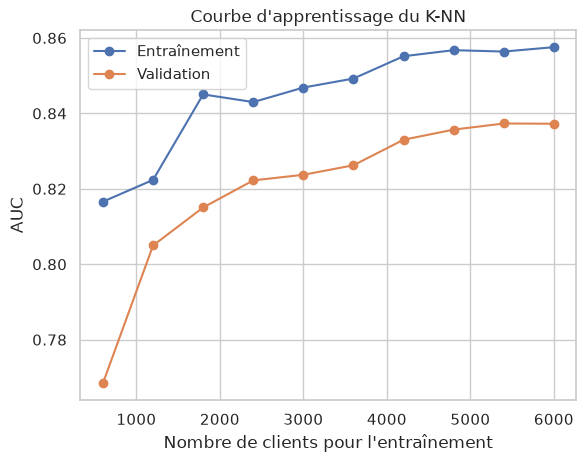

In [14]:
from sklearn.model_selection import learning_curve

knn_optimal = KNeighborsClassifier(n_neighbors=meilleur_k)
tailles_train, scores_train, scores_val = learning_curve(
    knn_optimal, X_train, y_train, cv=5, scoring='roc_auc', train_sizes=np.linspace(0.1, 1.0, 10)
)

plt.figure()
plt.plot(tailles_train, scores_train.mean(axis=1), label="Entraînement", marker='o')
plt.plot(tailles_train, scores_val.mean(axis=1), label="Validation", marker='o')
plt.xlabel("Nombre de clients pour l'entraînement")
plt.ylabel("AUC")
plt.title("Courbe d'apprentissage du K-NN")
plt.legend()
plt.show()

L'écart entre entraînement et validation se réduit quand les données augmentent (0,05 avec 600 clients, 0,02 avec
6 000 clients), et la validation progresse encore légèrement jusqu'à 0,837. Le K-NN garde un peu de variance, qui
diminue avec la taille de l'échantillon.

### 3.2 Arbre de décision (CART)

Choix de la profondeur par validation croisée (sur le train uniquement)
Profondeur  2 -> AUC train : 0.737 | AUC validation croisée : 0.725
Profondeur  3 -> AUC train : 0.793 | AUC validation croisée : 0.786


Profondeur  4 -> AUC train : 0.821 | AUC validation croisée : 0.803
Profondeur  5 -> AUC train : 0.845 | AUC validation croisée : 0.823


Profondeur  6 -> AUC train : 0.861 | AUC validation croisée : 0.825
Profondeur  8 -> AUC train : 0.895 | AUC validation croisée : 0.810


Profondeur 15 -> AUC train : 0.995 | AUC validation croisée : 0.695


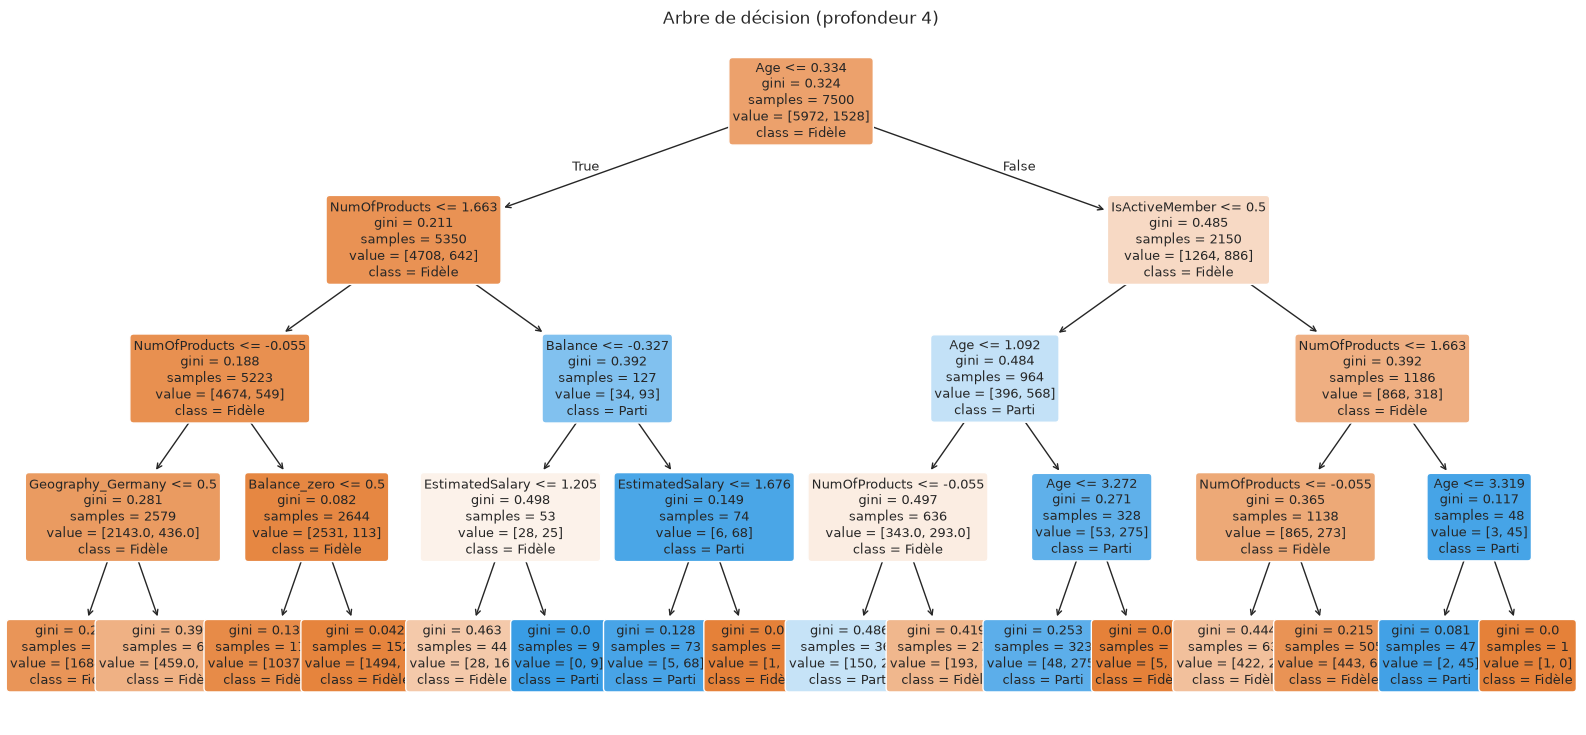

In [15]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

profondeurs = [2, 3, 4, 5, 6, 8, 15]
print("Choix de la profondeur par validation croisée (sur le train uniquement)")
for prof in profondeurs:
    arbre = DecisionTreeClassifier(max_depth=prof, random_state=42)
    auc_cv = cross_val_score(arbre, X_train, y_train, cv=5, scoring='roc_auc').mean()
    arbre.fit(X_train, y_train)
    auc_train = roc_auc_score(y_train, arbre.predict_proba(X_train)[:, 1])
    print(f"Profondeur {prof:>2} -> AUC train : {auc_train:.3f} | AUC validation croisée : {auc_cv:.3f}")

arbre_4 = DecisionTreeClassifier(max_depth=4, random_state=42)
arbre_4.fit(X_train, y_train)

plt.figure(figsize=(20, 9))
plot_tree(arbre_4, feature_names=list(X_train.columns), class_names=['Fidèle', 'Parti'],
          filled=True, rounded=True, fontsize=9)
plt.title("Arbre de décision (profondeur 4)")
plt.show()

Les profondeurs 5 et 6 font jeu égal en validation croisée (0,823 et 0,825) : je retiens **5**, plus simple. Au-delà,
l'arbre apprend par cœur : à profondeur 15, l'AUC d'entraînement atteint 0,995 mais la validation chute à 0,695.

Pour la lisibilité, j'affiche l'arbre de profondeur 4 (les seuils sont en valeurs standardisées). Sa première coupure
se fait sur l'**âge**, vers 42 ans. Ensuite, chez les plus jeunes, il regarde le **nombre de produits** ; chez les plus
âgés, le **statut actif**. C'est cohérent avec l'exploration de la Partie 1.

In [16]:
# Élagage par coût-complexité : alpha choisi par validation croisée
arbre_complet = DecisionTreeClassifier(random_state=42)
alphas = arbre_complet.cost_complexity_pruning_path(X_train, y_train).ccp_alphas

recherche_alpha = GridSearchCV(DecisionTreeClassifier(random_state=42), {'ccp_alpha': alphas}, cv=5, scoring='roc_auc')
recherche_alpha.fit(X_train, y_train)
arbre_elague = recherche_alpha.best_estimator_

arbre_5 = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)

print("Meilleur alpha :", round(recherche_alpha.best_params_['ccp_alpha'], 5))
print(f"Arbre élagué      -> profondeur {arbre_elague.get_depth()}, {arbre_elague.get_n_leaves()} feuilles, "
      f"AUC test {roc_auc_score(y_test, arbre_elague.predict_proba(X_test)[:, 1]):.3f}")
print(f"Arbre profondeur 5 -> profondeur {arbre_5.get_depth()}, {arbre_5.get_n_leaves()} feuilles, "
      f"AUC test {roc_auc_score(y_test, arbre_5.predict_proba(X_test)[:, 1]):.3f}")

Meilleur alpha : 0.00069
Arbre élagué      -> profondeur 7, 28 feuilles, AUC test 0.844
Arbre profondeur 5 -> profondeur 5, 28 feuilles, AUC test 0.849


L'arbre élagué descend jusqu'à 7 niveaux mais ne garde que 28 feuilles : il ne développe que les branches qui apportent
vraiment de l'information, alors qu'un arbre à profondeur fixe se développe partout de la même façon. Ses performances
(AUC de 0,844) sont proches de celles de l'arbre de profondeur 5, qui a le même nombre de feuilles. Pour présenter des
règles à des équipes métier, l'arbre de profondeur 4 (16 feuilles) reste le plus simple à lire.

## Partie 4 — Méthodes d'ensemble

### 4.1 Forêt aléatoire et importance des variables

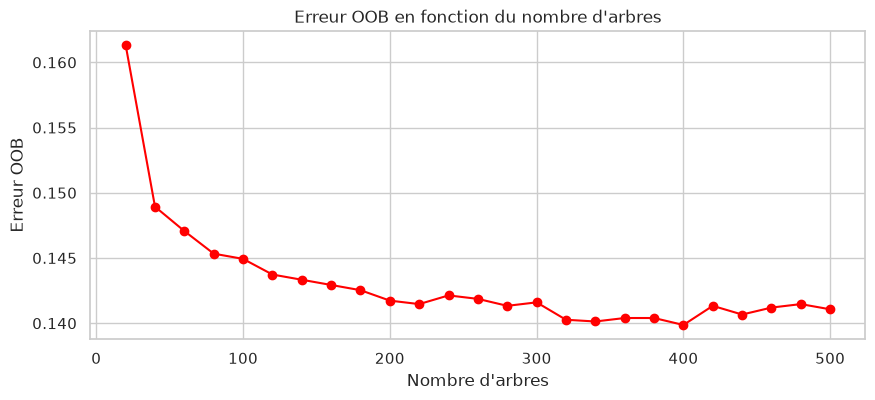

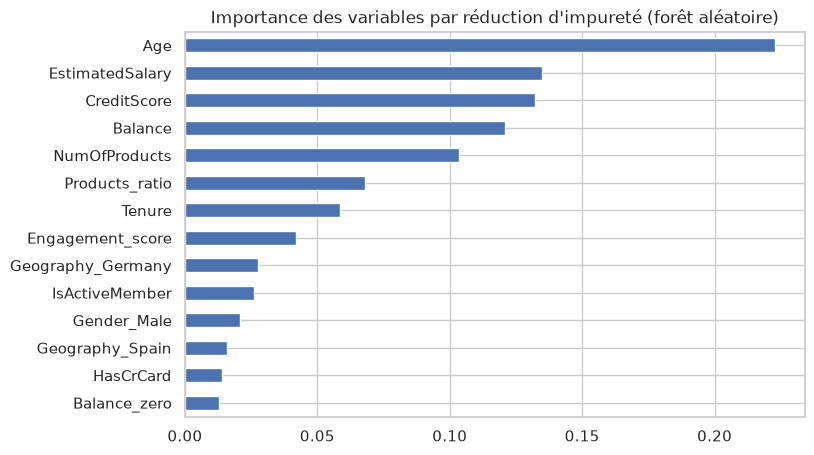

AUC entraînement : 1.000
AUC test : 0.863


In [17]:
from sklearn.ensemble import RandomForestClassifier

# warm_start : on ajoute des arbres à la même forêt pour suivre l'erreur OOB
foret_500 = RandomForestClassifier(oob_score=True, warm_start=True, random_state=42)
erreurs_oob = []
liste_arbres = range(20, 501, 20)
for n in liste_arbres:
    foret_500.set_params(n_estimators=n)
    foret_500.fit(X_train, y_train)
    erreurs_oob.append(1 - foret_500.oob_score_)

plt.figure(figsize=(10, 4))
plt.plot(liste_arbres, erreurs_oob, marker='o', color='red')
plt.title("Erreur OOB en fonction du nombre d'arbres")
plt.xlabel("Nombre d'arbres")
plt.ylabel("Erreur OOB")
plt.show()

importances = pd.Series(foret_500.feature_importances_, index=X_train.columns).sort_values()
plt.figure(figsize=(8, 5))
importances.plot(kind='barh')
plt.title("Importance des variables par réduction d'impureté (forêt aléatoire)")
plt.show()

print(f"AUC entraînement : {roc_auc_score(y_train, foret_500.predict_proba(X_train)[:, 1]):.3f}")
print(f"AUC test : {roc_auc_score(y_test, foret_500.predict_proba(X_test)[:, 1]):.3f}")

L'erreur OOB (calculée pour chaque client avec les arbres qui ne l'ont pas vu) baisse de 16,1 % avec 20 arbres à
environ 14 % vers 200 arbres, puis se stabilise : au-delà, ajouter des arbres n'apporte plus rien. La forêt atteint une
AUC de 1,0 sur l'entraînement contre 0,863 sur le test : elle apprend l'entraînement par cœur, mais généralise quand
même mieux que l'arbre seul.

Son importance par réduction d'impureté place en tête l'âge, puis le salaire estimé et le score de crédit, deux
variables que le Lasso jugeait faibles. Cette divergence mérite une vérification : je calcule l'**importance par
permutation**, qui mesure la perte d'AUC sur le test quand on mélange les valeurs d'une variable.

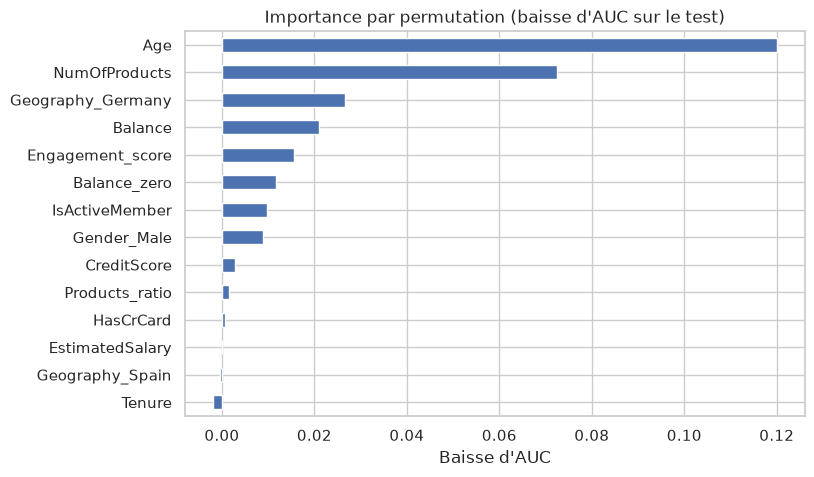

Age                  0.1200
NumOfProducts        0.0725
Geography_Germany    0.0266
Balance              0.0211
Engagement_score     0.0156
Balance_zero         0.0118
IsActiveMember       0.0097
Gender_Male          0.0088
CreditScore          0.0028
Products_ratio       0.0015
HasCrCard            0.0008
EstimatedSalary      0.0001
Geography_Spain     -0.0003
Tenure              -0.0019
dtype: float64


In [18]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(foret_500, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1)
importances_perm = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 5))
importances_perm.plot(kind='barh')
plt.title("Importance par permutation (baisse d'AUC sur le test)")
plt.xlabel("Baisse d'AUC")
plt.show()

print(importances_perm.sort_values(ascending=False).round(4))

L'importance par permutation raconte une autre histoire : l'**âge** (0,120 d'AUC perdue quand on mélange ses
valeurs) et le **nombre de produits** (0,073) dominent, suivis de l'Allemagne (0,027) et du solde (0,021). Le score de
crédit (0,003) et le salaire estimé (0,000) tombent presque à zéro.

La « divergence » venait donc de la méthode de calcul : l'importance par impureté favorise les variables continues qui
prennent beaucoup de valeurs différentes, comme le salaire ou le score de crédit. Mesurée sur le test, l'importance
**donne raison au Lasso** : les deux modèles s'accordent sur le rôle central de l'âge et du nombre de produits.

### 4.2 Optimisation des hyperparamètres de la forêt

In [19]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

rf_defaut = RandomForestClassifier(random_state=42)
rf_defaut.fit(X_train, y_train)
auc_defaut = roc_auc_score(y_test, rf_defaut.predict_proba(X_test)[:, 1])

grille = {
    'n_estimators': [100, 300, 500],
    'max_features': ['sqrt', 'log2', 0.3],
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
recherche_rf = RandomizedSearchCV(RandomForestClassifier(random_state=42), param_distributions=grille,
                                  n_iter=20, cv=cv_strat, scoring='roc_auc', n_jobs=-1, random_state=42)
recherche_rf.fit(X_train, y_train)

meilleur_rf = recherche_rf.best_estimator_
auc_optimise = roc_auc_score(y_test, meilleur_rf.predict_proba(X_test)[:, 1])

print("Hyperparamètres retenus :", recherche_rf.best_params_)
print(f"AUC avec les valeurs par défaut : {auc_defaut:.4f}")
print(f"AUC avec les hyperparamètres optimisés : {auc_optimise:.4f}")
print(f"Gain d'AUC : +{auc_optimise - auc_defaut:.4f}")

Hyperparamètres retenus : {'n_estimators': 100, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 10}
AUC avec les valeurs par défaut : 0.8589
AUC avec les hyperparamètres optimisés : 0.8687
Gain d'AUC : +0.0098


La recherche aléatoire teste 20 combinaisons au lieu des 81 possibles, ce qui va beaucoup plus vite. Le meilleur réglage
(100 arbres, profondeur maximale de 10, 30 % des variables testées à chaque coupure) fait passer l'AUC de 0,859 à 0,869,
soit un gain d'environ 1 point. Limiter la profondeur réduit aussi le surapprentissage.

### 4.3 HistGradientBoosting avec arrêt précoce

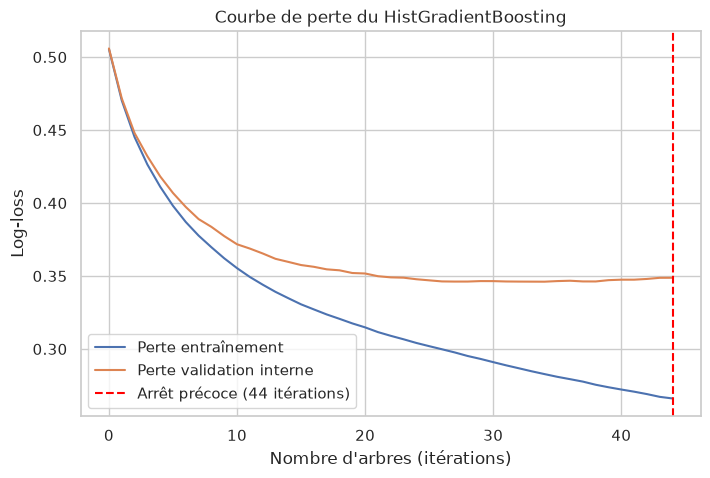

Arrêt précoce après 44 itérations
AUC test : 0.874


In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Arrêt précoce : 10 % du train servent de validation interne, et l'apprentissage s'arrête
# quand la perte de validation ne s'améliore plus pendant 10 itérations
hgb = HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=42)
hgb.fit(X_train, y_train)

perte_train = -hgb.train_score_
perte_val = -hgb.validation_score_
iterations = range(len(perte_train))

plt.figure(figsize=(8, 5))
plt.plot(iterations, perte_train, label='Perte entraînement')
plt.plot(iterations, perte_val, label='Perte validation interne')
plt.axvline(x=hgb.n_iter_, color='red', linestyle='--', label=f'Arrêt précoce ({hgb.n_iter_} itérations)')
plt.title("Courbe de perte du HistGradientBoosting")
plt.xlabel("Nombre d'arbres (itérations)")
plt.ylabel("Log-loss")
plt.legend()
plt.show()

print("Arrêt précoce après", hgb.n_iter_, "itérations")
print(f"AUC test : {roc_auc_score(y_test, hgb.predict_proba(X_test)[:, 1]):.3f}")

L'arrêt précoce interrompt l'apprentissage après 44 itérations, quand la perte de validation cesse de baisser :
continuer n'aurait servi qu'à apprendre le bruit. Le modèle atteint une AUC de **0,874** sur le test, la meilleure du projet.

### 4.4 Tableau de synthèse

In [21]:
import time
from sklearn.metrics import precision_score, recall_score

# Chaque modèle avec les réglages retenus plus haut
modeles = {
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=42),
    "Forêt aléatoire (optimisée)": RandomForestClassifier(**recherche_rf.best_params_, random_state=42),
    "Arbre de décision (profondeur 5)": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Régression Lasso": LogisticRegression(penalty='l1', solver='liblinear', random_state=42, C=recherche_lasso.best_params_['C'], max_iter=1000),
}

resultats = []
for nom, modele in modeles.items():
    debut = time.time()
    modele.fit(X_train, y_train)
    duree = time.time() - debut

    y_pred = modele.predict(X_test)
    y_prob = modele.predict_proba(X_test)[:, 1]
    resultats.append({
        "Modèle": nom,
        "AUC": round(roc_auc_score(y_test, y_prob), 3),
        "F1-score": round(f1_score(y_test, y_pred), 3),
        "Précision": round(precision_score(y_test, y_pred), 3),
        "Rappel": round(recall_score(y_test, y_pred), 3),
        "Temps (s)": round(duree, 2),
    })

df_synthese = pd.DataFrame(resultats).sort_values(by="AUC", ascending=False).reset_index(drop=True)
df_synthese

,Modèle,AUC,F1-score,Précision,Rappel,Temps (s)
0,HistGradientBoosting,0.874,0.604,0.775,0.495,0.14
1,Forêt aléatoire (optimisée),0.869,0.594,0.820,0.466,0.66
2,Arbre de décision (profondeur 5),0.849,0.553,0.799,0.422,0.02
3,Régression Lasso,0.847,0.495,0.729,0.375,0.16


Le **HistGradientBoosting** offre le meilleur compromis : la meilleure AUC (0,874) et le meilleur F1-score (0,604), pour
un entraînement d'une fraction de seconde. La forêt optimisée le suit de près (0,869) mais s'entraîne plusieurs fois
plus lentement. La précision et le rappel dépendent du seuil de 0,5 utilisé par défaut ; pour une campagne de
rétention, on utilise plutôt le **classement** des clients par score (Partie 6). Je retiens donc le HistGradientBoosting.

## Partie 5 — Courbes d'apprentissage et compromis biais-variance

### 5.1 Courbes d'apprentissage

HistGradientBoosting -> AUC entraînement : 0.941 | AUC validation : 0.855 (avec 6000 clients)


Régression Ridge -> AUC entraînement : 0.829 | AUC validation : 0.827 (avec 6000 clients)


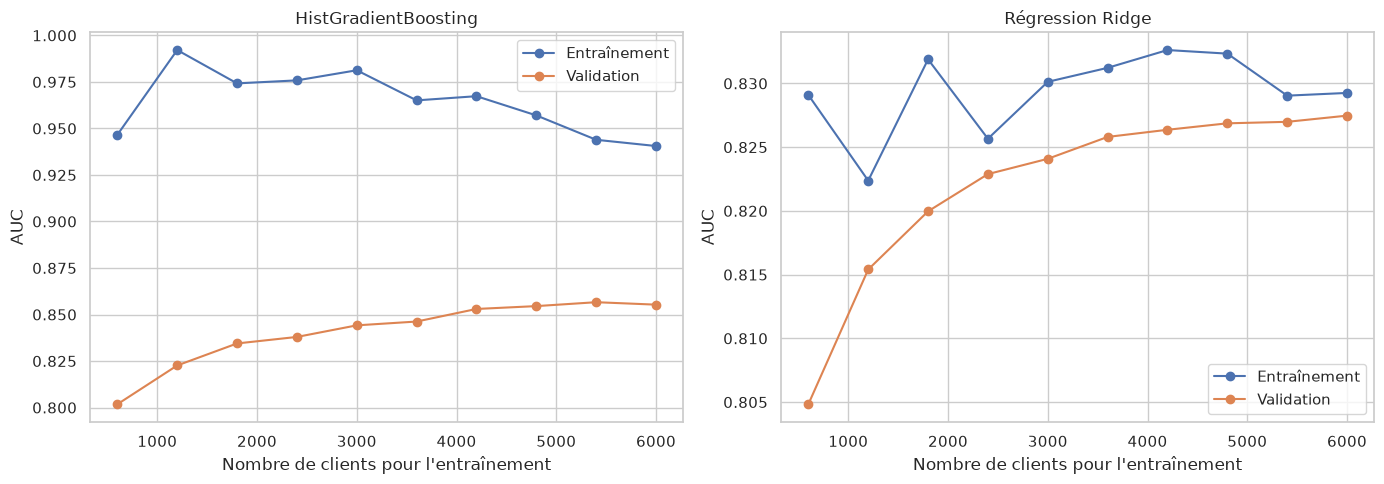

In [22]:
def tracer_courbe(modele, X, y, titre, ax):
    tailles, scores_train, scores_val = learning_curve(
        modele, X, y, cv=5, scoring='roc_auc', train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
    )
    ax.plot(tailles, scores_train.mean(axis=1), 'o-', label="Entraînement")
    ax.plot(tailles, scores_val.mean(axis=1), 'o-', label="Validation")
    ax.set_title(titre)
    ax.set_xlabel("Nombre de clients pour l'entraînement")
    ax.set_ylabel("AUC")
    ax.legend()
    print(f"{titre} -> AUC entraînement : {scores_train.mean(axis=1)[-1]:.3f} | "
          f"AUC validation : {scores_val.mean(axis=1)[-1]:.3f} (avec {tailles[-1]} clients)")

modele_ridge_simple = LogisticRegression(penalty='l2', C=1.0, solver='liblinear', random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tracer_courbe(HistGradientBoostingClassifier(max_iter=500, early_stopping=True, random_state=42),
              X_train, y_train, "HistGradientBoosting", axes[0])
tracer_courbe(modele_ridge_simple, X_train, y_train, "Régression Ridge", axes[1])
plt.tight_layout()
plt.show()

1. **HistGradientBoosting** : le score d'entraînement reste très élevé (entre 0,94 et 0,99) alors que la validation
   plafonne autour de 0,855. Cet écart traduit une **variance** marquée : le modèle apprend une partie du bruit. La
   validation progresse encore jusqu'à environ 5 000 clients : ce modèle a besoin de beaucoup de données.
2. **Ridge** : les deux courbes sont presque collées (0,829 contre 0,827 à la fin) et se stabilisent dès 2 000 à 3 000
   clients. Peu de variance, mais un plafond plus bas : c'est un **biais**, car le modèle linéaire est trop simple pour
   tout capter.
3. C'est le compromis biais-variance : le modèle complexe l'emporte quand les données sont nombreuses, le modèle simple
   est plus stable. D'où la question suivante : que se passe-t-il quand les données sont rares ?

### 5.2 Simulation avec seulement 500 clients

In [23]:
X_train_500, _, y_train_500, _ = train_test_split(X_train, y_train, train_size=500, stratify=y_train, random_state=42)

rf_rare = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train_500, y_train_500)
ridge_rare = LogisticRegression(penalty='l2', C=1.0, solver='liblinear', random_state=42).fit(X_train_500, y_train_500)

print(f"Forêt aléatoire : AUC test {roc_auc_score(y_test, rf_rare.predict_proba(X_test)[:, 1]):.3f}")
print(f"Régression Ridge : AUC test {roc_auc_score(y_test, ridge_rare.predict_proba(X_test)[:, 1]):.3f}")

Forêt aléatoire : AUC test 0.828
Régression Ridge : AUC test 0.820


Avec seulement 500 clients, la forêt aléatoire (0,828) et la régression Ridge (0,820) font presque jeu égal, alors que
la forêt avait une nette avance avec 7 500 clients. **Principe de parcimonie** : quand les données sont rares, un modèle
simple, plus stable et plus facile à expliquer, suffit.

## Partie 6 — Interprétation et recommandations métier

Pour toute cette partie, j'utilise le modèle retenu : le HistGradientBoosting de la partie 4.3.

### 6.1 Le modèle est-il bien calibré ?

Je découpe les clients du test en 5 segments de taille égale selon leur score, puis je compare, dans chaque segment, le
taux de départ prédit au taux réellement observé.

In [24]:
score_test = hgb.predict_proba(X_test)[:, 1]

df_business = pd.DataFrame({'Taux réel (%)': y_test, 'Taux prédit (%)': score_test})
df_business['Segment de risque'] = pd.qcut(df_business['Taux prédit (%)'], q=5,
                                           labels=['1 - Très faible', '2 - Faible', '3 - Moyen', '4 - Fort', '5 - Très fort'])

calibration = df_business.groupby('Segment de risque', observed=False).mean() * 100
calibration.round(1)

,Taux réel (%),Taux prédit (%)
Segment de risque,,
1 - Très faible,2.2,2.4
2 - Faible,4.0,5.5
3 - Moyen,9.2,10.0
4 - Fort,21.4,21.8
5 - Très fort,65.0,62.6


Le modèle est **bien calibré** : dans chaque segment, le taux prédit est proche du taux observé. Dans le segment le plus
risqué, il annonce 62,6 % de départs pour 65,0 % réellement observés ; dans le moins risqué, 2,4 % pour 2,2 %. La banque
peut donc utiliser ces probabilités telles quelles pour dimensionner son budget de rétention.

### 6.2 Combien de départs repère-t-on en ciblant les clients les plus risqués ?

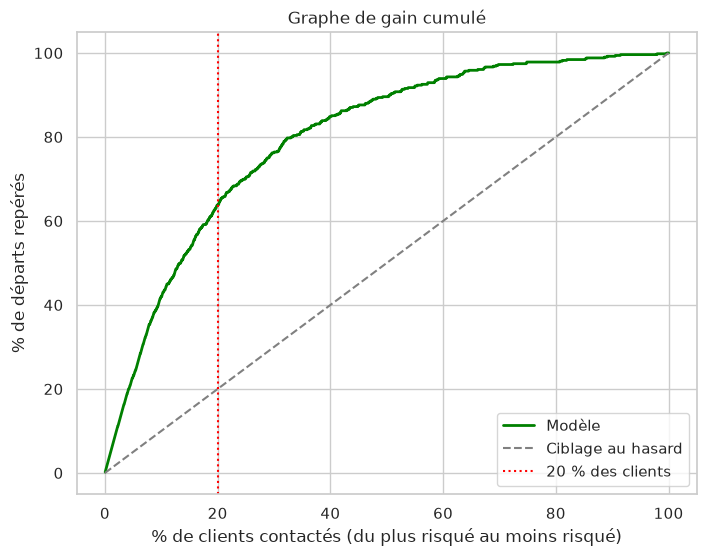

En contactant les 20 % de clients les plus à risque, on repère 63.9 % des départs.


In [25]:
df_gain = pd.DataFrame({'Vrai_Churn': y_test.values, 'Score_Pred': score_test})
df_gain = df_gain.sort_values(by='Score_Pred', ascending=False).reset_index(drop=True)
df_gain['Clients_Contactes_pct'] = (df_gain.index + 1) / len(df_gain) * 100
df_gain['Resiliants_Captures_pct'] = df_gain['Vrai_Churn'].cumsum() / df_gain['Vrai_Churn'].sum() * 100

plt.figure(figsize=(8, 6))
plt.plot(df_gain['Clients_Contactes_pct'], df_gain['Resiliants_Captures_pct'], label='Modèle', color='green', linewidth=2)
plt.plot([0, 100], [0, 100], linestyle='--', color='gray', label='Ciblage au hasard')
plt.axvline(x=20, color='red', linestyle=':', label='20 % des clients')
plt.title("Graphe de gain cumulé")
plt.xlabel("% de clients contactés (du plus risqué au moins risqué)")
plt.ylabel("% de départs repérés")
plt.legend()
plt.show()

gain_20 = df_gain.loc[df_gain['Clients_Contactes_pct'] <= 20, 'Resiliants_Captures_pct'].max()
print(f"En contactant les 20 % de clients les plus à risque, on repère {gain_20:.1f} % des départs.")

En contactant les **20 %** de clients les plus à risque, la banque repère **63,9 %** des départs, soit 3,2 fois plus
qu'un ciblage au hasard (qui en repérerait 20 %).

### 6.3 Profil des 5 % de clients les plus à risque

In [26]:
# Profil des 5 % de clients les plus à risque, en valeurs réelles (données non standardisées)
profils = df.loc[X_test.index].copy()
profils['Score'] = score_test
top_5 = profils.nlargest(int(len(profils) * 0.05), 'Score')

def resume(groupe):
    return pd.Series({
        "Âge moyen": groupe['Age'].mean(),
        "Solde moyen": groupe['Balance'].mean(),
        "Nombre moyen de produits": groupe['NumOfProducts'].mean(),
        "Part de clients en Allemagne (%)": (groupe['Geography'] == 'Germany').mean() * 100,
        "Part de femmes (%)": (groupe['Gender'] == 'Female').mean() * 100,
        "Part de clients actifs (%)": groupe['IsActiveMember'].mean() * 100,
        "Taux de départ réel (%)": groupe['Exited'].mean() * 100,
    })

comparaison = pd.DataFrame({"Ensemble du test": resume(profils), "Top 5 % les plus à risque": resume(top_5)})
display(comparaison.round(1))
print("Répartition du nombre de produits dans le top 5 % :", top_5['NumOfProducts'].value_counts().sort_index().to_dict())

,Ensemble du test,Top 5 % les plus à risque
Âge moyen,38.7,50.7
Solde moyen,76959.0,100762.4
Nombre moyen de produits,1.5,2.1
Part de clients en Allemagne (%),25.5,52.0
Part de femmes (%),46.9,55.2
Part de clients actifs (%),51.0,21.6
Taux de départ réel (%),20.4,93.6


Répartition du nombre de produits dans le top 5 % : {1: 61, 2: 6, 3: 42, 4: 16}


Les 5 % de clients les plus risqués partent effectivement à 93,6 %. Par rapport à l'ensemble des clients, ils sont :

- **plus âgés** : 50,7 ans en moyenne contre 38,7 ;
- **mieux dotés** : 100 762 de solde moyen contre 76 959 ;
- **souvent clients en Allemagne** : 52,0 % contre 25,5 % ;
- **peu actifs** : 21,6 % de clients actifs contre 51,0 % ;
- un peu plus souvent **des femmes** : 55,2 % contre 46,9 %.

Côté produits, on retrouve l'effet en U : presque tous détiennent un seul produit (61 clients) ou 3 à 4 produits
(58 clients), très peu en ont 2 (6 clients).

### 6.4 Transposition à l'assurance

**Équivalence des variables**

- L'âge et le pays restent identiques.
- `Tenure` devient l'ancienneté du contrat d'assurance.
- `NumOfProducts` devient le nombre de polices souscrites (auto, habitation…).
- `Balance` correspond au montant de la prime annuelle.

**Fuite d'information à éviter.** En assurance non-vie, la résiliation se décide à une date d'échéance annuelle. Un
découpage aléatoire (`train_test_split`) laisserait le modèle « tricher » avec le temps. Il faut un **découpage
temporel** : entraînement sur les comportements de l'année N−1, test sur les échéances de l'année N.

**Actions de rétention selon le segment de risque**

- Risque faible à moyen : campagne d'e-mailing avec un tarif préférentiel pour regrouper tous ses contrats.
- Risque fort : appel préventif du conseiller deux mois avant l'échéance, pour un bilan personnalisé.
- Risque très fort (top 5 %) : geste commercial proactif, par exemple 10 % de réduction ou un mois de cotisation offert.

## Conclusion

Un modèle de scoring bien construit n'est pas qu'un exercice technique : c'est un outil de décision. Le
HistGradientBoosting offre le meilleur compromis entre performance et rapidité (AUC de 0,874). Ses probabilités sont
fiables (bonne calibration) et il est rentable : 64 % des départs repérés en ne contactant que 20 % des clients.

Ce projet m'a aussi appris à **vérifier mes interprétations** : une hypothèse intuitive peut être fausse (le compte vide),
des coefficients peuvent tromper à cause de la colinéarité, et l'importance par impureté peut surestimer certaines
variables. Enfin, la complexité ne se justifie que si les données sont assez nombreuses : sinon, un modèle simple suffit.

**Pistes d'amélioration :** ajuster le seuil de décision au coût réel d'une action de rétention, et valider le modèle
sur une période plus récente (découpage temporel).